# Parte 2: Pérdida dado incumplimiento (LGD)

Decisiones, justificaciones y resultados en [`docs/parte2_lgd.md`](../docs/parte2_lgd.md).

In [1]:
import json
import os
import random
import time

import joblib
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.linear_model import LinearRegression
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from torch.utils.data import DataLoader, TensorDataset

C:\Users\Usuario\Documents\GitHub\RedesNeuronales_Trabajo2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
CONFIG = {
    "semilla": 56,
    "frac_train": 0.70,          # partición temporal por issue_d; lo más reciente queda en prueba
    "frac_val": 0.15,
    "capas_ocultas": [64, 32, 16],
    "activacion": "relu",        # relu | tanh | leaky_relu
    "dropout": 0.2,
    "perdida": "bce",            # bce | mse
    "lr": 1e-3,
    "weight_decay": 1e-4,        # penalización L2
    "batch_size": 512,
    "epocas": 100,
    "paciencia": 10,             # parada temprana
    "n_busqueda": 30,            # configuraciones de la búsqueda aleatoria
    "n_semillas": 30,
    "rehacer_experimentos": False,  # False: carga búsqueda y semillas de ../resultados si existen
}

ESPACIO_BUSQUEDA = {
    "capas_ocultas": [[32], [64], [64, 32], [128, 64], [64, 32, 16], [128, 64, 32]],
    "activacion": ["relu", "tanh", "leaky_relu"],
    "dropout": [0.0, 0.1, 0.2, 0.3],
    "weight_decay": [0.0, 1e-5, 1e-4, 1e-3],
    "lr": [1e-4, 3e-4, 1e-3, 3e-3],
    "batch_size": [256, 512, 1024],
    "perdida": ["bce", "mse"],
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando: {device}")

Usando: cpu


## 1. Carga del conjunto original

In [3]:
ruta_dataset = kagglehub.dataset_download("ranadeep/credit-risk-dataset")
df_og = pd.read_csv(os.path.join(ruta_dataset, "loan", "loan.csv"), low_memory=False)
df_og["issue_d"] = pd.to_datetime(df_og["issue_d"], format="%b-%Y")

print(f"Registros: {df_og.shape[0]:,} | Variables: {df_og.shape[1]}")
print(f"Originación: {df_og['issue_d'].min():%Y-%m} a {df_og['issue_d'].max():%Y-%m}")

Registros: 887,379 | Variables: 74
Originación: 2007-06 a 2015-12


## 2. Variable objetivo

In [4]:
estados_malos = [
    "Charged Off",
    "Default",
    "Late (31-120 days)",
    "Does not meet the credit policy. Status:Charged Off",
]
df_og[df_og["loan_status"].isin(estados_malos)].groupby("loan_status").agg(
    n=("loan_status", "size"),
    pct_con_recuperacion=("recoveries", lambda s: round((s > 0).mean() * 100, 2)),
    out_prncp_promedio=("out_prncp", "mean"),
)

,n,pct_con_recuperacion,out_prncp_promedio
loan_status,,,
Charged Off,45248,53.45,0.000000
Default,1219,0.00,11594.991559
Does not meet the credit policy. Status:Charged Off,761,64.39,0.000000
Late (31-120 days),11591,0.00,11689.555921


In [5]:
# Default y Late no tienen recuperaciones aún: solo los castigados tienen LGD observable
estados_castigados = ["Charged Off", "Does not meet the credit policy. Status:Charged Off"]
df_lgd = df_og[df_og["loan_status"].isin(estados_castigados)].copy()

df_lgd["ead"] = df_lgd["funded_amnt"] - df_lgd["total_rec_prncp"]
df_lgd["recuperacion_neta"] = df_lgd["recoveries"] - df_lgd["collection_recovery_fee"]
lgd_sin_recorte = 1 - df_lgd["recuperacion_neta"] / df_lgd["ead"]

print("EAD > 0:", (df_lgd["ead"] > 0).all(), "| out_prncp = 0:", (df_lgd["out_prncp"] == 0).all())
print(f"LGD < 0 antes del recorte: {(lgd_sin_recorte < 0).sum()} | LGD > 1: {(lgd_sin_recorte > 1).sum()}")

df_lgd["lgd"] = lgd_sin_recorte.clip(0, 1)
print(f"Créditos castigados: {len(df_lgd):,}")
print(df_lgd["lgd"].describe())
print(f"LGD = 1: {(df_lgd['lgd'] == 1).mean():.2%}")

EAD > 0: True | out_prncp = 0: True
LGD < 0 antes del recorte: 38 | LGD > 1: 0
Créditos castigados: 46,009
count    46009.000000
mean         0.929627
std          0.098287
min          0.000000
25%          0.859686
50%          0.981310
75%          1.000000
max          1.000000
Name: lgd, dtype: float64
LGD = 1: 46.36%


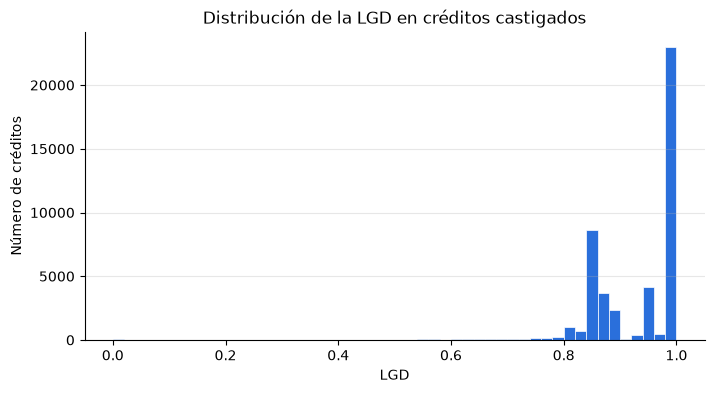

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df_lgd["lgd"], bins=50, color="#2a6fdb", edgecolor="white", linewidth=0.5)
ax.set_xlabel("LGD")
ax.set_ylabel("Número de créditos")
ax.set_title("Distribución de la LGD en créditos castigados")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [7]:
con_recuperacion = df_lgd[df_lgd["recoveries"] > 0]
print("recoveries / EAD más frecuentes:")
print((con_recuperacion["recoveries"] / con_recuperacion["ead"]).round(3).value_counts().head(5))
print("\ncollection_recovery_fee / recoveries más frecuentes:")
print((con_recuperacion["collection_recovery_fee"] / con_recuperacion["recoveries"]).round(3).value_counts().head(5))

recoveries / EAD más frecuentes:
0.057    2298
0.142    1640
0.141    1523
0.143    1489
0.144    1332
Name: count, dtype: int64

collection_recovery_fee / recoveries más frecuentes:
0.010    11023
0.180     8510
0.000     1175
0.009      937
0.011      429
Name: count, dtype: int64


In [8]:
df_lgd.groupby(df_lgd["issue_d"].dt.year).agg(
    n=("lgd", "size"),
    lgd_promedio=("lgd", "mean"),
    pct_sin_recuperacion=("recoveries", lambda s: round((s == 0).mean() * 100, 2)),
)

,n,lgd_promedio,pct_sin_recuperacion
issue_d,,,
2007,158,0.920709,36.71
2008,496,0.930762,44.15
2009,723,0.925746,34.02
2010,1753,0.924567,25.61
2011,3205,0.922166,22.65
2012,8084,0.911364,25.16
2013,14836,0.917851,42.90
2014,13981,0.945151,62.72
2015,2773,0.980747,88.97


## 3. Variables de entrada

In [9]:
# Mismas variables y codificaciones que procesamiento.ipynb
columnas_entrada = [
    "loan_amnt", "funded_amnt", "funded_amnt_inv", "term", "int_rate", "installment",
    "grade", "sub_grade", "emp_length", "home_ownership", "annual_inc",
    "verification_status", "pymnt_plan", "purpose", "dti", "delinq_2yrs",
    "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc",
    "initial_list_status", "collections_12_mths_ex_med", "application_type",
    "acc_now_delinq", "tot_coll_amt", "tot_cur_bal", "total_rev_hi_lim",
]
df_lgd = df_lgd.dropna(subset=columnas_entrada)
X = df_lgd[columnas_entrada].copy()

letras = ["A", "B", "C", "D", "E", "F", "G"]
X["grade"] = X["grade"].map({l: i for i, l in enumerate(letras)})
X["sub_grade"] = X["sub_grade"].map(
    {f"{l}{n}": i for i, (l, n) in enumerate((l, n) for l in letras for n in range(1, 6))}
)
X["verification_status"] = X["verification_status"].map(
    {"Not Verified": 0, "Source Verified": 1, "Verified": 2}
)
X["emp_length"] = X["emp_length"].map(
    {"< 1 year": 0, "1 year": 1, **{f"{i} years": i for i in range(2, 10)}, "10+ years": 10}
)

columnas_categoricas = X.select_dtypes(exclude="number").columns.tolist()
X = pd.get_dummies(X, columns=columnas_categoricas, drop_first=True, dtype=int)

# Columnas constantes en los castigados (pymnt_plan, application_type) no aportan información
X = X.loc[:, X.nunique() > 1]

# ead se guarda solo para la sección de pérdida esperada; no es variable de entrada
df_modelo = pd.concat([df_lgd[["id", "issue_d"]], X, df_lgd[["ead", "lgd"]]], axis=1)
print(f"Registros: {len(df_modelo):,} | Variables de entrada: {X.shape[1]}")

Registros: 33,110 | Variables de entrada: 41


In [10]:
df_modelo.to_csv("../datasets/df_lgd_procesado.csv.gz", index=False)

## 4. Partición temporal

In [11]:
df_modelo = df_modelo.sort_values("issue_d").reset_index(drop=True)
corte_val = df_modelo["issue_d"].quantile(CONFIG["frac_train"])
corte_test = df_modelo["issue_d"].quantile(CONFIG["frac_train"] + CONFIG["frac_val"])

particion = np.select(
    [df_modelo["issue_d"] < corte_val, df_modelo["issue_d"] < corte_test],
    ["train", "val"],
    default="test",
)
df_modelo.groupby(particion).agg(
    n=("lgd", "size"),
    desde=("issue_d", "min"),
    hasta=("issue_d", "max"),
    lgd_promedio=("lgd", "mean"),
).loc[["train", "val", "test"]]

,n,desde,hasta,lgd_promedio
train,22372,2012-08-01,2014-04-01,0.918809
val,5511,2014-05-01,2014-09-01,0.949423
test,5227,2014-10-01,2015-09-01,0.969753


In [12]:
columnas_x = X.columns.tolist()
X_train, y_train = df_modelo.loc[particion == "train", columnas_x], df_modelo.loc[particion == "train", "lgd"]
X_val, y_val = df_modelo.loc[particion == "val", columnas_x], df_modelo.loc[particion == "val", "lgd"]
X_test, y_test = df_modelo.loc[particion == "test", columnas_x], df_modelo.loc[particion == "test", "lgd"]

# Escalado a [-1, 1] con mínimo y máximo de entrenamiento
x_min, x_max = X_train.min(), X_train.max()
escalar = lambda df: -1 + 2 * (df - x_min) / (x_max - x_min)
X_train, X_val, X_test = escalar(X_train), escalar(X_val), escalar(X_test)

## 5. Modelo de referencia: regresión lineal

In [13]:
def metricas(y, pred):
    return {"MAE": mean_absolute_error(y, pred), "RMSE": root_mean_squared_error(y, pred)}


inicio = time.perf_counter()
lineal = LinearRegression().fit(X_train, y_train)
segundos_lineal = time.perf_counter() - inicio
n_param_lineal = lineal.coef_.size + 1
print(f"Parámetros entrenables: {n_param_lineal} | Tiempo de ajuste: {segundos_lineal:.2f} s")

pred_lineal = {nombre: lineal.predict(X_) for nombre, X_ in [("val", X_val), ("test", X_test)]}
print(f"Predicciones fuera de [0, 1] en prueba: {((pred_lineal['test'] < 0) | (pred_lineal['test'] > 1)).mean():.2%}")

Parámetros entrenables: 42 | Tiempo de ajuste: 0.05 s
Predicciones fuera de [0, 1] en prueba: 0.00%


## 6. Perceptrón multicapa

In [14]:
ACTIVACIONES = {"relu": nn.ReLU, "tanh": nn.Tanh, "leaky_relu": nn.LeakyReLU}


class LGDNN(nn.Module):
    def __init__(self, input_dim, capas_ocultas, activacion="relu", dropout=0.2):
        super().__init__()
        capas, entrada = [], input_dim
        for neuronas in capas_ocultas:
            capas += [
                nn.Linear(entrada, neuronas),
                nn.BatchNorm1d(neuronas),
                ACTIVACIONES[activacion](),
                nn.Dropout(dropout),
            ]
            entrada = neuronas
        capas.append(nn.Linear(entrada, 1))
        self.network = nn.Sequential(*capas)

    def forward(self, x):
        # Devuelve el logit; la LGD es sigmoid(logit)
        return self.network(x).squeeze(1)


def perdida(logits, y, tipo):
    if tipo == "bce":
        return nn.functional.binary_cross_entropy_with_logits(logits, y)
    return nn.functional.mse_loss(torch.sigmoid(logits), y)


def fijar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)


a_tensor = lambda df: torch.tensor(df.to_numpy(), dtype=torch.float32).to(device)
X_train_t, X_val_t, X_test_t = a_tensor(X_train), a_tensor(X_val), a_tensor(X_test)
y_train_t, y_val_t = a_tensor(y_train), a_tensor(y_val)

In [15]:
def entrenar_mlp(config, semilla, verbose=True):
    fijar_semilla(semilla)
    modelo = LGDNN(X_train_t.shape[1], config["capas_ocultas"], config["activacion"], config["dropout"]).to(device)
    optimizer = torch.optim.Adam(modelo.parameters(), lr=config["lr"], weight_decay=config["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=3, factor=0.5)
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=config["batch_size"], shuffle=True)

    historia = {"train_loss": [], "val_loss": []}
    mejor_val, mejor_estado, sin_mejora = float("inf"), None, 0

    for epoca in range(1, config["epocas"] + 1):
        modelo.train()
        total = 0.0
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = perdida(modelo(X_batch), y_batch, config["perdida"])
            loss.backward()
            optimizer.step()
            total += loss.item() * len(y_batch)

        modelo.eval()
        with torch.no_grad():
            val_loss = perdida(modelo(X_val_t), y_val_t, config["perdida"]).item()
        scheduler.step(val_loss)
        historia["train_loss"].append(total / len(y_train_t))
        historia["val_loss"].append(val_loss)

        if val_loss < mejor_val:
            mejor_val, sin_mejora = val_loss, 0
            mejor_estado = {k: v.clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1

        if verbose and (epoca % 5 == 0 or epoca == 1):
            print(f"Época {epoca:03d} | train: {historia['train_loss'][-1]:.4f} | val: {val_loss:.4f} | lr: {optimizer.param_groups[0]['lr']:.1e}")
        if sin_mejora >= config["paciencia"]:
            if verbose:
                print(f"Parada temprana en la época {epoca}; mejor val: {mejor_val:.4f}")
            break

    modelo.load_state_dict(mejor_estado)
    return modelo, historia


def predecir(modelo, X_t):
    modelo.eval()
    with torch.no_grad():
        return torch.sigmoid(modelo(X_t)).cpu().numpy()

In [16]:
def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


def muestrear_config(rng):
    return {k: v[rng.integers(len(v))] for k, v in ESPACIO_BUSQUEDA.items()}


os.makedirs("../resultados", exist_ok=True)
ruta_busqueda = "../resultados/busqueda_lgd.csv"
ruta_semillas = "../resultados/semillas_lgd.csv"
ruta_config_final = "../resultados/config_final_lgd.json"
rehacer = CONFIG["rehacer_experimentos"] or not all(
    os.path.exists(r) for r in [ruta_busqueda, ruta_semillas, ruta_config_final]
)
print("Se reentrenan búsqueda y semillas" if rehacer else "Se cargan resultados guardados en ../resultados")

Se cargan resultados guardados en ../resultados


## 7. Búsqueda aleatoria de hiperparámetros

In [17]:
if rehacer:
    rng = np.random.default_rng(CONFIG["semilla"])
    filas = []
    for i in range(CONFIG["n_busqueda"]):
        config_i = {**CONFIG, **muestrear_config(rng)}
        inicio = time.perf_counter()
        modelo_i, historia_i = entrenar_mlp(config_i, CONFIG["semilla"], verbose=False)
        fila = {k: config_i[k] for k in ESPACIO_BUSQUEDA}
        fila |= {
            "parametros": contar_parametros(modelo_i),
            "epocas": len(historia_i["val_loss"]),
            **{f"{m}_val": v for m, v in metricas(y_val, predecir(modelo_i, X_val_t)).items()},
            "segundos": time.perf_counter() - inicio,
        }
        filas.append(fila)
        print(f"{i + 1:02d}/{CONFIG['n_busqueda']} | RMSE val: {fila['RMSE_val']:.4f} | {fila['segundos']:.1f} s")
    busqueda = pd.DataFrame(filas)
    busqueda.to_csv(ruta_busqueda, index=False)
else:
    busqueda = pd.read_csv(ruta_busqueda)
    busqueda["capas_ocultas"] = busqueda["capas_ocultas"].apply(json.loads)

busqueda = busqueda.sort_values("RMSE_val").reset_index(drop=True)
print(f"Configuraciones: {len(busqueda)} | Tiempo total: {busqueda['segundos'].sum() / 60:.1f} min")
busqueda.head(10).round(4)

Configuraciones: 30 | Tiempo total: 5.7 min


,capas_ocultas,activacion,dropout,weight_decay,lr,batch_size,perdida,parametros,epocas,MAE_val,RMSE_val,segundos
0,"[64, 32, 16]",tanh,0.2,0.0000,0.0003,512,mse,5537,97,0.0657,0.0772,24.8350
1,"[128, 64]",tanh,0.3,0.0000,0.0010,256,mse,14081,20,0.0645,0.0773,8.8077
2,[32],relu,0.3,0.0000,0.0010,256,mse,1441,22,0.0653,0.0775,4.7715
3,[64],tanh,0.1,0.0000,0.0010,256,bce,2881,15,0.0653,0.0779,4.8179
4,"[128, 64, 32]",leaky_relu,0.3,0.0000,0.0003,256,mse,16193,47,0.0686,0.0783,17.5576
5,[64],leaky_relu,0.3,0.0001,0.0010,1024,mse,2881,34,0.0693,0.0787,6.3461
6,"[64, 32]",tanh,0.2,0.0010,0.0010,512,mse,4993,39,0.0706,0.0788,11.5075
7,[32],tanh,0.3,0.0001,0.0030,256,bce,1441,12,0.0688,0.0790,3.5714
8,"[64, 32]",relu,0.2,0.0000,0.0010,1024,mse,4993,49,0.0695,0.0790,13.4405
9,"[64, 32, 16]",leaky_relu,0.2,0.0001,0.0003,512,mse,5537,61,0.0702,0.0791,19.8875


In [18]:
# Criterio de selección: menor RMSE en validación
mejor = busqueda.iloc[0][list(ESPACIO_BUSQUEDA)]
config_final = {**CONFIG, **{k: (v.item() if hasattr(v, "item") else v) for k, v in mejor.items()}}
if rehacer:
    with open(ruta_config_final, "w") as f:
        json.dump(config_final, f, indent=2)
{k: config_final[k] for k in ESPACIO_BUSQUEDA}

{'capas_ocultas': [64, 32, 16],
 'activacion': 'tanh',
 'dropout': 0.2,
 'weight_decay': 1e-05,
 'lr': 0.0003,
 'batch_size': 512,
 'perdida': 'mse'}

## 8. Configuración final con 30 semillas

In [19]:
if rehacer:
    filas = []
    for semilla in range(CONFIG["n_semillas"]):
        inicio = time.perf_counter()
        modelo_s, historia_s = entrenar_mlp(config_final, semilla, verbose=False)
        filas.append({
            "semilla": semilla,
            "epocas": len(historia_s["val_loss"]),
            **{f"{m}_val": v for m, v in metricas(y_val, predecir(modelo_s, X_val_t)).items()},
            **{f"{m}_test": v for m, v in metricas(y_test, predecir(modelo_s, X_test_t)).items()},
            "segundos": time.perf_counter() - inicio,
        })
    semillas = pd.DataFrame(filas)
    semillas.to_csv(ruta_semillas, index=False)
else:
    semillas = pd.read_csv(ruta_semillas)

print(f"Tiempo total: {semillas['segundos'].sum() / 60:.1f} min")
resumen_semillas = semillas[["MAE_val", "RMSE_val", "MAE_test", "RMSE_test"]].agg(["mean", "std", "min", "max"])
resumen_semillas.index = ["media", "desv. estándar", "mejor", "peor"]
resumen_semillas.round(4)

Tiempo total: 13.6 min


,MAE_val,RMSE_val,MAE_test,RMSE_test
media,0.0655,0.0775,0.0618,0.0796
desv. estándar,0.0007,0.0002,0.0012,0.0005
mejor,0.0643,0.0771,0.0598,0.0787
peor,0.0675,0.0779,0.0653,0.0811


## 9. Modelo final

In [20]:
mlp, historia = entrenar_mlp(config_final, CONFIG["semilla"])
n_param_mlp = contar_parametros(mlp)
print(mlp)
print(f"Parámetros entrenables: {n_param_mlp:,}")

Época 001 | train: 0.1465 | val: 0.1597 | lr: 3.0e-04
Época 005 | train: 0.1005 | val: 0.0989 | lr: 3.0e-04
Época 010 | train: 0.0506 | val: 0.0456 | lr: 3.0e-04
Época 015 | train: 0.0285 | val: 0.0223 | lr: 3.0e-04
Época 020 | train: 0.0189 | val: 0.0127 | lr: 3.0e-04
Época 025 | train: 0.0147 | val: 0.0089 | lr: 3.0e-04
Época 030 | train: 0.0129 | val: 0.0074 | lr: 3.0e-04
Época 035 | train: 0.0119 | val: 0.0067 | lr: 3.0e-04
Época 040 | train: 0.0113 | val: 0.0064 | lr: 3.0e-04
Época 045 | train: 0.0110 | val: 0.0062 | lr: 3.0e-04
Época 050 | train: 0.0107 | val: 0.0061 | lr: 3.0e-04
Época 055 | train: 0.0105 | val: 0.0060 | lr: 3.0e-04
Época 060 | train: 0.0105 | val: 0.0060 | lr: 3.0e-04
Época 065 | train: 0.0104 | val: 0.0060 | lr: 3.0e-04
Época 070 | train: 0.0102 | val: 0.0060 | lr: 1.5e-04
Época 075 | train: 0.0101 | val: 0.0060 | lr: 1.5e-04
Época 080 | train: 0.0100 | val: 0.0060 | lr: 7.5e-05
Época 085 | train: 0.0102 | val: 0.0060 | lr: 3.7e-05
Época 090 | train: 0.0101 | 

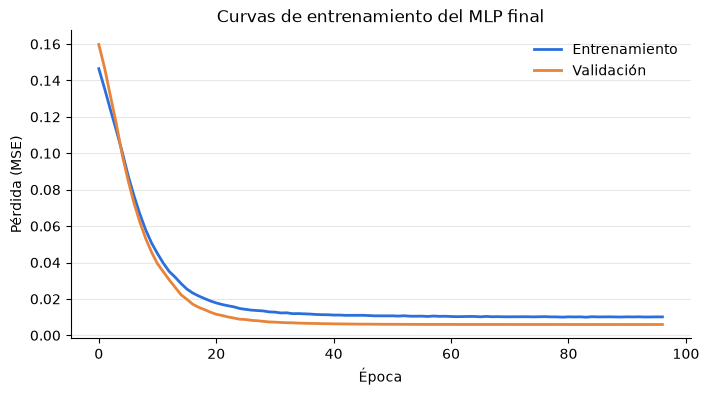

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(historia["train_loss"], label="Entrenamiento", color="#2a6fdb", linewidth=2)
ax.plot(historia["val_loss"], label="Validación", color="#e8833a", linewidth=2)
ax.set_xlabel("Época")
ax.set_ylabel(f"Pérdida ({config_final['perdida'].upper()})")
ax.set_title("Curvas de entrenamiento del MLP final")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 10. Comparación

In [22]:
pd.DataFrame({
    "parametros": [1, n_param_lineal, n_param_mlp],
    "configuraciones_busqueda": [1, 1, len(busqueda)],
    "segundos_busqueda": [0.0, segundos_lineal, busqueda["segundos"].sum()],
    "segundos_30_semillas": [0.0, 0.0, semillas["segundos"].sum()],
}, index=["Media de entrenamiento", "Regresión lineal", "MLP"]).round(2)

,parametros,configuraciones_busqueda,segundos_busqueda,segundos_30_semillas
Media de entrenamiento,1,1,0.00,0.00
Regresión lineal,42,1,0.05,0.00
MLP,5537,30,339.78,814.64


In [23]:
pred_lineal["train"] = lineal.predict(X_train)
pred_mlp = {n: predecir(mlp, X_t) for n, X_t in [("train", X_train_t), ("val", X_val_t), ("test", X_test_t)]}
y_real = {"train": y_train, "val": y_val, "test": y_test}
pred_media = {n: np.full(len(y_), y_train.mean()) for n, y_ in y_real.items()}

# sesgo: error de nivel; spearman: capacidad de ordenar créditos, independiente del nivel
filas = []
for modelo, preds in [("Media de entrenamiento", pred_media), ("Regresión lineal", pred_lineal), ("MLP", pred_mlp)]:
    for nombre in ["train", "val", "test"]:
        y_, p_ = y_real[nombre].to_numpy(), preds[nombre]
        filas.append({
            "modelo": modelo,
            "conjunto": nombre,
            **metricas(y_, p_),
            "RMSE_sin_sesgo": np.sqrt(np.mean(((y_ - y_.mean()) - (p_ - p_.mean())) ** 2)),
            "sesgo": p_.mean() - y_.mean(),
            "spearman": spearmanr(y_, p_).statistic if len(np.unique(p_)) > 1 else np.nan,
        })
pd.DataFrame(filas).set_index(["modelo", "conjunto"]).round(4)

MAE    RMSE  RMSE_sin_sesgo   sesgo  \
modelo                 conjunto                                           
Media de entrenamiento train     0.0755  0.0920          0.0920  0.0000   
                       val       0.0770  0.0834          0.0776 -0.0306   
                       test      0.0814  0.0919          0.0765 -0.0509   
Regresión lineal       train     0.0731  0.0910          0.0910  0.0000   
                       val       0.0716  0.0801          0.0771 -0.0215   
                       test      0.0740  0.0878          0.0773 -0.0418   
MLP                    train     0.0744  0.0948          0.0913  0.0255   
                       val       0.0657  0.0772          0.0771 -0.0017   
                       test      0.0630  0.0800          0.0766 -0.0232   

                                 spearman  
modelo                 conjunto            
Media de entrenamiento train          NaN  
                       val            NaN  
                       test           NaN  
Regresión lineal       train       0.1993  
                       val         0.1535  
                       test        0.1402  
MLP                    train       0.1694  
                       val         0.1515  
                       test        0.1062

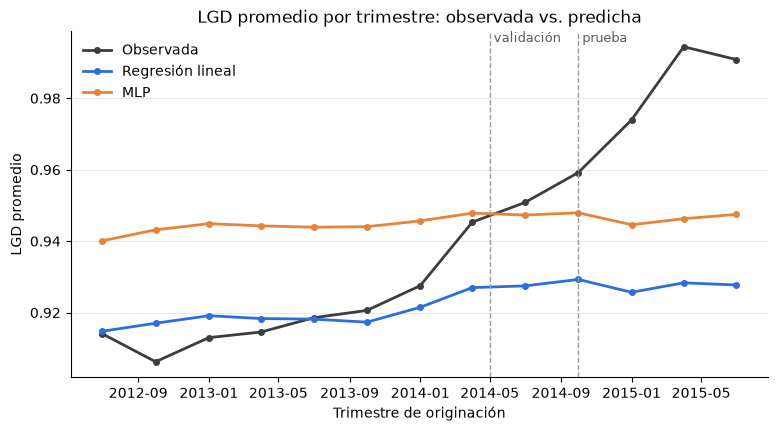

In [24]:
X_todo = escalar(df_modelo[columnas_x])
por_trimestre = pd.DataFrame({
    "Observada": df_modelo["lgd"],
    "Regresión lineal": lineal.predict(X_todo),
    "MLP": predecir(mlp, a_tensor(X_todo)),
}).groupby(df_modelo["issue_d"].dt.to_period("Q").dt.start_time).mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
for columna, color in [("Observada", "#3d3d3d"), ("Regresión lineal", "#2a6fdb"), ("MLP", "#e8833a")]:
    ax.plot(por_trimestre.index, por_trimestre[columna], label=columna, color=color, linewidth=2, marker="o", markersize=4)
for corte, texto in [(corte_val, "validación"), (corte_test, "prueba")]:
    ax.axvline(corte, color="#9a9a9a", linestyle="--", linewidth=1)
    ax.text(corte, ax.get_ylim()[1], f" {texto}", va="top", color="#5a5a5a", fontsize=9)
ax.set_xlabel("Trimestre de originación")
ax.set_ylabel("LGD promedio")
ax.set_title("LGD promedio por trimestre: observada vs. predicha")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [25]:
cuantiles = [0.05, 0.25, 0.5, 0.75, 0.95]
pd.DataFrame({
    "Observada": y_test.quantile(cuantiles).to_numpy(),
    "Regresión lineal": np.quantile(pred_lineal["test"], cuantiles),
    "MLP": np.quantile(pred_mlp["test"], cuantiles),
}, index=[f"p{int(q * 100)}" for q in cuantiles]).T.assign(
    desv_estandar=[y_test.std(), pred_lineal["test"].std(), pred_mlp["test"].std()]
).round(4)

,p5,p25,p50,p75,p95,desv_estandar
Observada,0.8484,1.0000,1.0000,1.0000,1.0000,0.0766
Regresión lineal,0.9028,0.9176,0.9279,0.9398,0.9514,0.0180
MLP,0.9290,0.9397,0.9479,0.9555,0.9583,0.0103


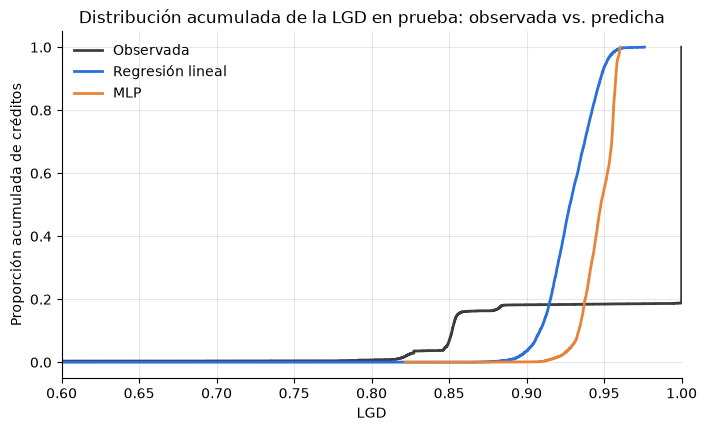

In [26]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for etiqueta, valores, color in [
    ("Observada", y_test.to_numpy(), "#3d3d3d"),
    ("Regresión lineal", pred_lineal["test"], "#2a6fdb"),
    ("MLP", pred_mlp["test"], "#e8833a"),
]:
    x = np.sort(valores)
    ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", label=etiqueta, color=color, linewidth=2)
ax.set_xlim(0.6, 1.0)
ax.set_xlabel("LGD")
ax.set_ylabel("Proporción acumulada de créditos")
ax.set_title("Distribución acumulada de la LGD en prueba: observada vs. predicha")
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 11. Exposición al incumplimiento y pérdida esperada

In [27]:
# EAD al originar: monto desembolsado por la fracción promedio que queda pendiente al castigo,
# estimada por plazo con los castigados de entrenamiento
plazo_60 = df_modelo["term_ 60 months"] == 1
fraccion_pendiente = df_modelo["ead"] / df_modelo["funded_amnt"]
factor_ead = fraccion_pendiente[particion == "train"].groupby(plazo_60[particion == "train"]).mean()
factor_ead.index = factor_ead.index.map({False: "36 meses", True: "60 meses"})
print(factor_ead.round(4))

ead_estimada = df_modelo["funded_amnt"] * np.where(plazo_60, factor_ead["60 meses"], factor_ead["36 meses"])

term_ 60 months
36 meses    0.6697
60 meses    0.8459
dtype: float64


In [28]:
def perdida_esperada(pd_, lgd, ead):
    return pd_ * lgd * ead


# Validación en prueba: todos incumplieron (PD = 1), así que E[L] debe aproximar la pérdida observada
en_test = particion == "test"
perdida_real = df_modelo.loc[en_test, "lgd"] * df_modelo.loc[en_test, "ead"]
perdida_estimada = perdida_esperada(1.0, pred_mlp["test"], ead_estimada[en_test])

pd.DataFrame({
    "Pérdida observada": [perdida_real.sum(), perdida_real.mean()],
    "Pérdida estimada (MLP, EAD estimada)": [perdida_estimada.sum(), perdida_estimada.mean()],
}, index=["Total (USD)", "Promedio por crédito (USD)"]).T.round(0)

,Total (USD),Promedio por crédito (USD)
Pérdida observada,71196347.0,13621.0
"Pérdida estimada (MLP, EAD estimada)",57736333.0,11046.0


In [29]:
os.makedirs("../weights", exist_ok=True)
torch.save(
    {"state_dict": mlp.state_dict(), "config": config_final, "columnas": columnas_x},
    "../weights/modelo_lgd.pth",
)
joblib.dump(
    {"modelo": lineal, "x_min": x_min, "x_max": x_max, "columnas": columnas_x, "factor_ead": factor_ead},
    "../weights/regresion_lineal_lgd.joblib",
)
print("Modelos guardados en ../weights/")

Modelos guardados en ../weights/
